<a href="https://colab.research.google.com/github/yashkumarcs24-bmsce/Bio-Inspired-Systems-Lab/blob/main/Cuckoo_Search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# % -----------------------------------------------------------------
# % Cuckoo Search (CS) algorithm by Xin-She Yang and Suash Deb %
# % Programmed by Xin-She Yang at Cambridge University %
# % Programming dates: Nov 2008 to June 2009 %
# % Last revised: Dec 2009 (simplified version for demo only) %
# % -----------------------------------------------------------------
# % Papers -- Citation Details:
# % 1) X.-S. Yang, S. Deb, Cuckoo search via Levy flights,
# % in: Proc. of World Congress on Nature & Biologically Inspired
# % Computing (NaBIC 2009), December 2009, India,
# % IEEE Publications, USA, pp. 210-214 (2009).
# % http://arxiv.org/PS_cache/arxiv/pdf/1003/1003.1594v1.pdf
# % 2) X.-S. Yang, S. Deb, Engineering optimization by cuckoo search,
# % Int. J. Mathematical Modelling and Numerical Optimisation,
# % Vol. 1, No. 4, 330-343 (2010).
# % http://arxiv.org/PS_cache/arxiv/pdf/1005/1005.2908v2.pdf
# % ----------------------------------------------------------------%
# % This demo program only implements a standard version of %
# % Cuckoo Search (CS), as the Levy flights and generation of %
# % new solutions may use slightly different methods. %
# % The pseudo code was given sequentially (select a cuckoo etc), %
# % but the implementation here uses Matlab’s vector capability, %
# % which results in neater/better codes and shorter running time. %
# % This implementation is different and more efficient than the %
# % the demo code provided in the book by
# % "Yang X. S., Nature-Inspired Metaheuristic Algoirthms, %
# % 2nd Edition, Luniver Press, (2010). " %

# % --------------------------------------------------------------- %
# % =============================================================== %
# % Notes: %
# % Different implementations may lead to slightly different %
# % behavour and/or results, but there is nothing wrong with it, %
# % as this is the nature of random walks and all metaheuristics. %
# % -----------------------------------------------------------------
function [bestnest,fmin]=cuckoo_search(n)
  if nargin<1:
# % Number of nests (or different solutions)
n=25;
end
% Discovery rate of alien eggs/solutions
pa=0.25;
%% Change this if you want to get better results
% Tolerance
Tol=1.0e-5;
%% Simple bounds of the search domain
% Lower bounds
nd=15;
Lb=-5*ones(1,nd);
% Upper bounds
Ub=5*ones(1,nd);
% Random initial solutions
for i=1:n,
nest(i,:)=Lb+(Ub-Lb).*rand(size(Lb));
end
% Get the current best
fitness=10^10*ones(n,1);
[fmin,bestnest,nest,fitness]=get_best_nest(nest,nest,fitness);
N_iter=0;
%% Starting iterations
while (fmin>Tol),
% Generate new solutions (but keep the current best)
new_nest=get_cuckoos(nest,bestnest,Lb,Ub);
[fnew,best,nest,fitness]=get_best_nest(nest,new_nest,fitness);
% Update the counter
N_iter=N_iter+n;
% Discovery and randomization
new_nest=empty_nests(nest,Lb,Ub,pa) ;
% Evaluate this set of solutions
[fnew,best,nest,fitness]=get_best_nest(nest,new_nest,fitness);
% Update the counter again
N_iter=N_iter+n;
% Find the best objective so far


if fnew<fmin,
fmin=fnew;
bestnest=best;
end
end %% End of iterations
%% Post-optimization processing
%% Display all the nests
disp(strcat(’Total number of iterations=’,num2str(N_iter)));
fmin
bestnest
%% --------------- All subfunctions are list below ------------------
%% Get cuckoos by ramdom walk
function nest=get_cuckoos(nest,best,Lb,Ub)
% Levy flights
n=size(nest,1);
% Levy exponent and coefficient
% For details, see equation (2.21), Page 16 (chapter 2) of the book
% X. S. Yang, Nature-Inspired Metaheuristic Algorithms, 2nd Edition, Luniver Press, (2010).
beta=3/2;
sigma=(gamma(1+beta)*sin(pi*beta/2)/(gamma((1+beta)/2)*beta*2^((beta-1)/2)))^(1/beta);
for j=1:n,
s=nest(j,:);
% This is a simple way of implementing Levy flights
% For standard random walks, use step=1;
%% Levy flights by Mantegna’s algorithm
u=randn(size(s))*sigma;
v=randn(size(s));
step=u./abs(v).^(1/beta);
% In the next equation, the difference factor (s-best) means that
% when the solution is the best solution, it remains unchanged.
stepsize=0.01*step.*(s-best);
% Here the factor 0.01 comes from the fact that L/100 should the typical
% step size of walks/flights where L is the typical lenghtscale;
% otherwise, Levy flights may become too aggresive/efficient,
% which makes new solutions (even) jump out side of the design domain
% (and thus wasting evaluations).
% Now the actual random walks or flights
s=s+stepsize.*randn(size(s));
% Apply simple bounds/limits
nest(j,:)=simplebounds(s,Lb,Ub);
end
%% Find the current best nest
function [fmin,best,nest,fitness]=get_best_nest(nest,newnest,fitness)
% Evaluating all new solutions
for j=1:size(nest,1),
fnew=fobj(newnest(j,:));
if fnew<=fitness(j),
fitness(j)=fnew;
nest(j,:)=newnest(j,:);


end
end
% Find the current best
[fmin,K]=min(fitness) ;
best=nest(K,:);
%% Replace some nests by constructing new solutions/nests
function new_nest=empty_nests(nest,Lb,Ub,pa)
% A fraction of worse nests are discovered with a probability pa
n=size(nest,1);
% Discovered or not -- a status vector
K=rand(size(nest))>pa;
% In the real world, if a cuckoo’s egg is very similar to a host’s eggs, then
% this cuckoo’s egg is less likely to be discovered, thus the fitness should
% be related to the difference in solutions. Therefore, it is a good idea
% to do a random walk in a biased way with some random step sizes.
%% New solution by biased/selective random walks
stepsize=rand*(nest(randperm(n),:)-nest(randperm(n),:));
new_nest=nest+stepsize.*K;
% Application of simple constraints
function s=simplebounds(s,Lb,Ub)
% Apply the lower bound
ns_tmp=s;
I=ns_tmp<Lb;
ns_tmp(I)=Lb(I);
% Apply the upper bounds
J=ns_tmp>Ub;
ns_tmp(J)=Ub(J);
% Update this new move
s=ns_tmp;
%% You can replace the following by your own functions
% A d-dimensional objective function
function z=fobj(u)
%% d-dimensional sphere function sum_j=1^d (u_j-1)^2.
% with a minimum at (1,1, ...., 1);
z=sum((u-1).^2);


========== GRID OPTIMIZATION RESULTS ==========
Number of Jobs: 100
Number of Processors: 13
Number of Job Sets: 14

Optimized Task Allocation:
Processor 1: 7 jobs
Processor 2: 12 jobs
Processor 3: 8 jobs
Processor 4: 9 jobs
Processor 5: 5 jobs
Processor 6: 4 jobs
Processor 7: 5 jobs
Processor 8: 10 jobs
Processor 9: 9 jobs
Processor 10: 8 jobs
Processor 11: 3 jobs
Processor 12: 11 jobs
Processor 13: 9 jobs

Makespan: 69.466 seconds
Total Transfer Time: 66.294 seconds
Load Balance Score: 95.51 %
Best Fitness: 137.296


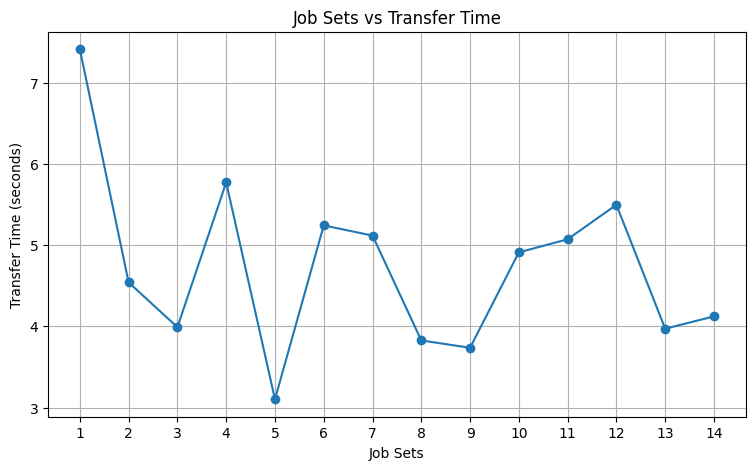

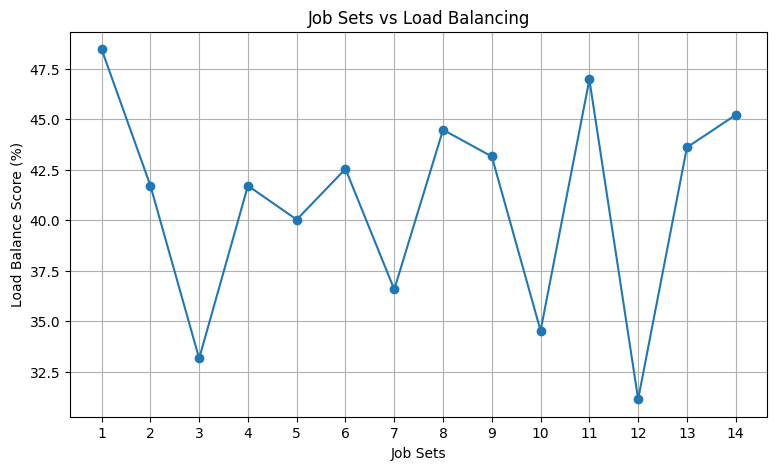

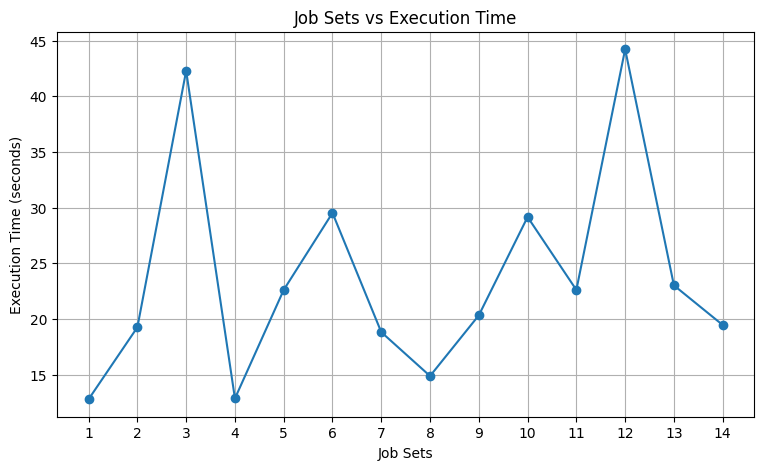

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import math

np.random.seed(42)

# ---------------- INPUTS ----------------
NUM_JOBS = 100
NUM_PROCESSORS = 13
NUM_JOBSETS = 14

NESTS = 25
MAX_ITER = 100
PA = 0.25

# Generate heterogeneous processor speeds
speeds = np.random.uniform(0.8, 2.0, NUM_PROCESSORS)

# Generate job workloads and data sizes
workloads = np.random.uniform(5, 20, NUM_JOBS)
data_size = np.random.uniform(1, 10, NUM_JOBS)

# Execution time matrix
execution = workloads[:, None] / speeds[None, :]
execution += np.random.uniform(0.1, 0.5, (NUM_JOBS, NUM_PROCESSORS))

# Transfer time matrix (bandwidth: 50-100 Mbps)
bandwidth = np.random.uniform(50, 100, NUM_PROCESSORS)
transfer = (data_size[:, None] * 8) / bandwidth[None, :]

# Divide jobs into 14 job sets
jobsets = np.array_split(np.arange(NUM_JOBS), NUM_JOBSETS)


# ---------------- FITNESS FUNCTION ----------------
def fitness(solution):
    loads = np.zeros(NUM_PROCESSORS)

    for job in range(NUM_JOBS):
        processor = solution[job]
        loads[processor] += execution[job, processor]

    makespan = np.max(loads)
    transfer_time = np.sum(transfer[np.arange(NUM_JOBS), solution])
    imbalance = np.std(loads)

    return makespan + transfer_time + 0.5 * imbalance


# ---------------- LEVY FLIGHT ----------------
def levy_flight():
    beta = 1.5
    sigma = (
        math.gamma(1 + beta) * math.sin(math.pi * beta / 2)
        / (math.gamma((1 + beta) / 2) * beta * 2 ** ((beta - 1) / 2))
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / (abs(v) ** (1 / beta) + 1e-10)


# ---------------- INITIAL POPULATION ----------------
nests = np.random.randint(
    0, NUM_PROCESSORS, (NESTS, NUM_JOBS)
)

scores = np.array([fitness(nest) for nest in nests])

best_index = np.argmin(scores)
best_solution = nests[best_index].copy()
best_fitness = scores[best_index]

convergence = []


# ---------------- CUCKOO SEARCH ----------------
for iteration in range(MAX_ITER):

    for i in range(NESTS):

        new_solution = nests[i].copy()

        # Lévy-flight-inspired task reassignment
        step = abs(levy_flight()) * 3
        changes = max(1, min(NUM_JOBS, int(step) + 1))

        selected_jobs = np.random.choice(
            NUM_JOBS, changes, replace=False
        )

        for job in selected_jobs:
            new_solution[job] = np.random.randint(NUM_PROCESSORS)

        new_score = fitness(new_solution)

        # Select a random nest
        j = np.random.randint(NESTS)

        if new_score < scores[j]:
            nests[j] = new_solution
            scores[j] = new_score

    # Abandon worst nests
    abandon_count = max(1, int(PA * NESTS))
    worst = np.argsort(scores)[-abandon_count:]

    for index in worst:
        nests[index] = np.random.randint(
            0, NUM_PROCESSORS, NUM_JOBS
        )
        scores[index] = fitness(nests[index])

    # Update global best
    current_best = np.argmin(scores)

    if scores[current_best] < best_fitness:
        best_fitness = scores[current_best]
        best_solution = nests[current_best].copy()

    convergence.append(best_fitness)


# ---------------- FINAL RESULTS ----------------
loads = np.zeros(NUM_PROCESSORS)

for job in range(NUM_JOBS):
    p = best_solution[job]
    loads[p] += execution[job, p]

makespan = np.max(loads)
total_transfer = np.sum(
    transfer[np.arange(NUM_JOBS), best_solution]
)

mean_load = np.mean(loads)
cv = np.std(loads) / (mean_load + 1e-10)
balance_score = 100 / (1 + cv)

print("\n========== GRID OPTIMIZATION RESULTS ==========")
print("Number of Jobs:", NUM_JOBS)
print("Number of Processors:", NUM_PROCESSORS)
print("Number of Job Sets:", NUM_JOBSETS)

print("\nOptimized Task Allocation:")
for i in range(NUM_PROCESSORS):
    assigned = np.where(best_solution == i)[0]
    print(f"Processor {i+1}: {len(assigned)} jobs")

print("\nMakespan:", round(makespan, 3), "seconds")
print("Total Transfer Time:", round(total_transfer, 3), "seconds")
print("Load Balance Score:", round(balance_score, 2), "%")
print("Best Fitness:", round(best_fitness, 3))


# ---------------- JOB SET METRICS ----------------
transfer_values = []
execution_values = []
balance_values = []

for group in jobsets:

    group_loads = np.zeros(NUM_PROCESSORS)
    group_transfer = 0

    for job in group:
        p = best_solution[job]
        group_loads[p] += execution[job, p]
        group_transfer += transfer[job, p]

    group_makespan = np.max(group_loads)

    mean = np.mean(group_loads)
    cv = np.std(group_loads) / (mean + 1e-10)
    group_balance = 100 / (1 + cv)

    transfer_values.append(group_transfer)
    execution_values.append(group_makespan)
    balance_values.append(group_balance)


# ---------------- THREE GRAPHS ----------------
x = np.arange(1, NUM_JOBSETS + 1)

plt.figure(figsize=(9, 5))
plt.plot(x, transfer_values, marker='o')
plt.title("Job Sets vs Transfer Time")
plt.xlabel("Job Sets")
plt.ylabel("Transfer Time (seconds)")
plt.grid(True)
plt.xticks(x)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(x, balance_values, marker='o')
plt.title("Job Sets vs Load Balancing")
plt.xlabel("Job Sets")
plt.ylabel("Load Balance Score (%)")
plt.grid(True)
plt.xticks(x)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(x, execution_values, marker='o')
plt.title("Job Sets vs Execution Time")
plt.xlabel("Job Sets")
plt.ylabel("Execution Time (seconds)")
plt.grid(True)
plt.xticks(x)
plt.show()


========== CUCKOO SEARCH GRID OPTIMIZATION ==========

Number of Jobs: 100
Number of Processors: 13
Number of Job Sets: 14

Optimized Job Allocation:
Processor 1: 5 jobs
Processor 2: 11 jobs
Processor 3: 9 jobs
Processor 4: 8 jobs
Processor 5: 6 jobs
Processor 6: 5 jobs
Processor 7: 4 jobs
Processor 8: 9 jobs
Processor 9: 10 jobs
Processor 10: 9 jobs
Processor 11: 5 jobs
Processor 12: 10 jobs
Processor 13: 9 jobs

========== PERFORMANCE METRICS ==========
Minimum Execution Time (Makespan): 68.77
Total Transfer Time: 62.42
Load Balancing Score: 0.9595
Best Fitness Value: 0.007488

========== JOB SET PERFORMANCE ==========
Job Set     Transfer Time     Load Balance      Execution Time    
1           6.57              0.4908            14.19             
2           4.57              0.5023            12.67             
3           3.93              0.3781            26.18             
4           4.85              0.5003            11.99             
5           2.56              0.414

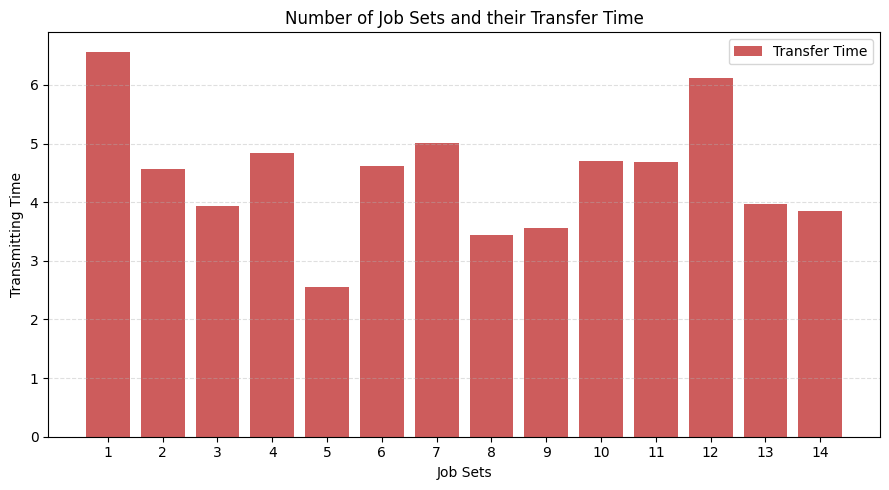

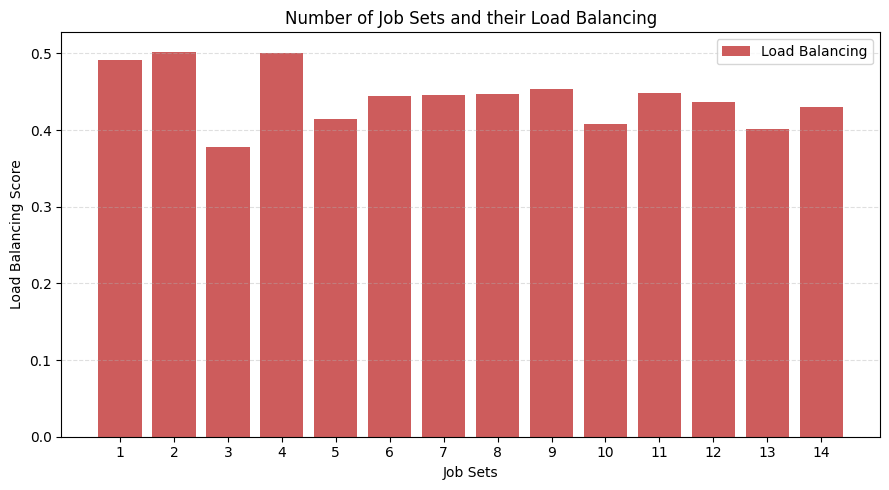

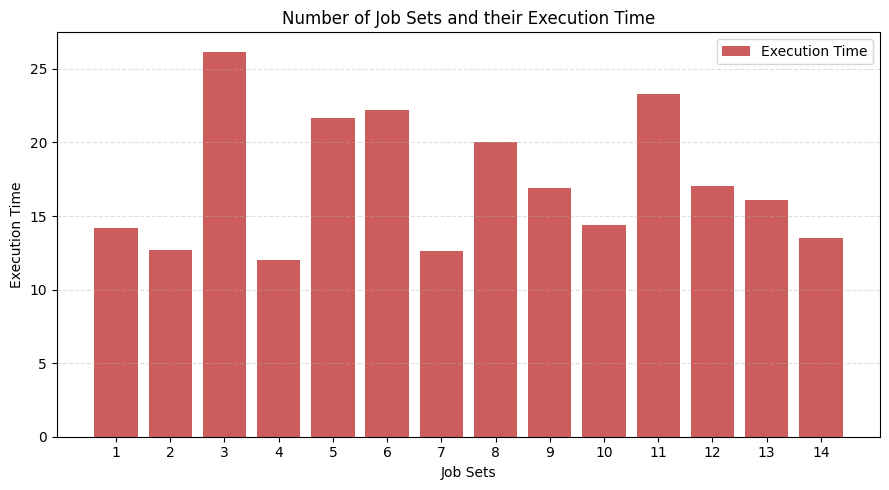

In [5]:

import numpy as np
import matplotlib.pyplot as plt
import math
# ---------------- INPUT PARAMETERS ----------------

NUM_JOBS = 100
NUM_PROCESSORS = 13
NUM_JOBSETS = 14

NESTS = 25
MAX_ITER = 100
PA = 0.25

np.random.seed(42)

# ---------------- GRID ENVIRONMENT ----------------

processor_speeds = np.random.uniform(0.8, 2.0, NUM_PROCESSORS)
job_workloads = np.random.uniform(5, 20, NUM_JOBS)
job_data_sizes = np.random.uniform(1, 10, NUM_JOBS)
bandwidth = np.random.uniform(50, 100, NUM_PROCESSORS)

execution_time = np.zeros((NUM_JOBS, NUM_PROCESSORS))
transfer_time = np.zeros((NUM_JOBS, NUM_PROCESSORS))

for i in range(NUM_JOBS):
    for j in range(NUM_PROCESSORS):
        execution_time[i][j] = (
            job_workloads[i] / processor_speeds[j]
            + np.random.uniform(0.1, 0.5)
        )

        transfer_time[i][j] = (
            job_data_sizes[i] * 8 / bandwidth[j]
        )

jobsets = np.array_split(np.arange(NUM_JOBS), NUM_JOBSETS)


# ---------------- FITNESS FUNCTION ----------------

def evaluate(solution):
    processor_loads = np.zeros(NUM_PROCESSORS)
    total_transfer = 0

    for job in range(NUM_JOBS):
        processor = solution[job]

        processor_loads[processor] += execution_time[job][processor]
        total_transfer += transfer_time[job][processor]

    makespan = np.max(processor_loads)
    load_deviation = np.std(processor_loads)

    cost = makespan + total_transfer + 0.5 * load_deviation

    fitness = 1 / (1 + cost)

    return fitness, makespan, total_transfer, processor_loads


# ---------------- LEVY FLIGHT ----------------


def levy_flight():
    beta = 1.5

    sigma = (
        math.gamma(1 + beta)
        * math.sin(math.pi * beta / 2)
        / (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / (abs(v) ** (1 / beta) + 1e-10)


# ---------------- INITIAL POPULATION ----------------

nests = np.random.randint(
    0, NUM_PROCESSORS, (NESTS, NUM_JOBS)
)

fitness_values = np.zeros(NESTS)

for i in range(NESTS):
    fitness_values[i] = evaluate(nests[i])[0]

best_index = np.argmax(fitness_values)
best_solution = nests[best_index].copy()
best_fitness = fitness_values[best_index]


# ---------------- CUCKOO SEARCH ALGORITHM ----------------

for iteration in range(MAX_ITER):

    for i in range(NESTS):

        new_solution = nests[i].copy()

        step = levy_flight()
        num_changes = max(1, int(abs(step) * NUM_JOBS * 0.05))

        for _ in range(num_changes):
            job = np.random.randint(NUM_JOBS)
            new_solution[job] = np.random.randint(NUM_PROCESSORS)

        new_fitness = evaluate(new_solution)[0]

        j = np.random.randint(NESTS)

        if new_fitness > fitness_values[j]:
            nests[j] = new_solution.copy()
            fitness_values[j] = new_fitness

    # Abandon a fraction of the worst nests
    num_abandoned = max(1, int(PA * NESTS))

    worst_indices = np.argsort(fitness_values)[:num_abandoned]

    for index in worst_indices:
        nests[index] = np.random.randint(
            0, NUM_PROCESSORS, NUM_JOBS
        )
        fitness_values[index] = evaluate(nests[index])[0]

    # Retain the best solution found so far
    current_best = np.argmax(fitness_values)

    if fitness_values[current_best] > best_fitness:
        best_fitness = fitness_values[current_best]
        best_solution = nests[current_best].copy()


# ---------------- FINAL RESULTS ----------------

best_fitness, makespan, total_transfer, processor_loads = evaluate(
    best_solution
)

load_balance_score = 1 / (
    1 + np.std(processor_loads) / (np.mean(processor_loads) + 1e-10)
)

print("\n========== CUCKOO SEARCH GRID OPTIMIZATION ==========")

print("\nNumber of Jobs:", NUM_JOBS)
print("Number of Processors:", NUM_PROCESSORS)
print("Number of Job Sets:", NUM_JOBSETS)

print("\nOptimized Job Allocation:")

for i in range(NUM_PROCESSORS):
    assigned_jobs = np.where(best_solution == i)[0]
    print(
        f"Processor {i + 1}: "
        f"{len(assigned_jobs)} jobs"
    )

print("\n========== PERFORMANCE METRICS ==========")

print(f"Minimum Execution Time (Makespan): {makespan:.2f}")
print(f"Total Transfer Time: {total_transfer:.2f}")
print(f"Load Balancing Score: {load_balance_score:.4f}")
print(f"Best Fitness Value: {best_fitness:.6f}")


# ---------------- JOB SET PERFORMANCE ----------------

jobset_transfer = []
jobset_execution = []
jobset_balance = []

for jobs in jobsets:

    loads = np.zeros(NUM_PROCESSORS)
    transfer = 0

    for job in jobs:
        processor = best_solution[job]

        loads[processor] += execution_time[job][processor]
        transfer += transfer_time[job][processor]

    jobset_makespan = np.max(loads)

    mean_load = np.mean(loads)
    std_load = np.std(loads)

    balance = 1 / (
        1 + std_load / (mean_load + 1e-10)
    )

    jobset_transfer.append(transfer)
    jobset_execution.append(jobset_makespan)
    jobset_balance.append(balance)


# ---------------- TEXTUAL JOB SET OUTPUT ----------------

print("\n========== JOB SET PERFORMANCE ==========")

print(
    f"{'Job Set':<12}"
    f"{'Transfer Time':<18}"
    f"{'Load Balance':<18}"
    f"{'Execution Time':<18}"
)

for i in range(NUM_JOBSETS):
    print(
        f"{i + 1:<12}"
        f"{jobset_transfer[i]:<18.2f}"
        f"{jobset_balance[i]:<18.4f}"
        f"{jobset_execution[i]:<18.2f}"
    )


# ---------------- GRAPH 1: TRANSFER TIME ----------------

jobset_numbers = np.arange(1, NUM_JOBSETS + 1)

plt.figure(figsize=(9, 5))

plt.bar(
    jobset_numbers,
    jobset_transfer,
    color='indianred',
    label='Transfer Time'
)

plt.xlabel("Job Sets")
plt.ylabel("Transmitting Time")
plt.title("Number of Job Sets and their Transfer Time")
plt.xticks(jobset_numbers)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


# ---------------- GRAPH 2: LOAD BALANCING ----------------

plt.figure(figsize=(9, 5))

plt.bar(
    jobset_numbers,
    jobset_balance,
    color='indianred',
    label='Load Balancing'
)

plt.xlabel("Job Sets")
plt.ylabel("Load Balancing Score")
plt.title("Number of Job Sets and their Load Balancing")
plt.xticks(jobset_numbers)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


# ---------------- GRAPH 3: EXECUTION TIME ----------------

plt.figure(figsize=(9, 5))

plt.bar(
    jobset_numbers,
    jobset_execution,
    color='indianred',
    label='Execution Time'
)

plt.xlabel("Job Sets")
plt.ylabel("Execution Time")
plt.title("Number of Job Sets and their Execution Time")
plt.xticks(jobset_numbers)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
